In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from matplotlib.colors import to_rgba
import warnings
warnings.filterwarnings("ignore")

# Cores utilizadas
CORES = {
    "laranja": "#E07A3D",
    "azul": "#2E5A88",
    "verde": "#3A7D5C",
    "roxo": "#6B4C9A",
    "cinza": "#5A5A5A",
    "cinza_claro": "#E8E8E8",
    "fundo": "#FAFAFA",
    "texto": "#222222",
}

# Frases Coloridas

O objetivo desse exemplo é destacar visualmente as diferentes ideias e limitações apresentadas em um texto, agrupando-as por categorias temáticas por meio de cores.

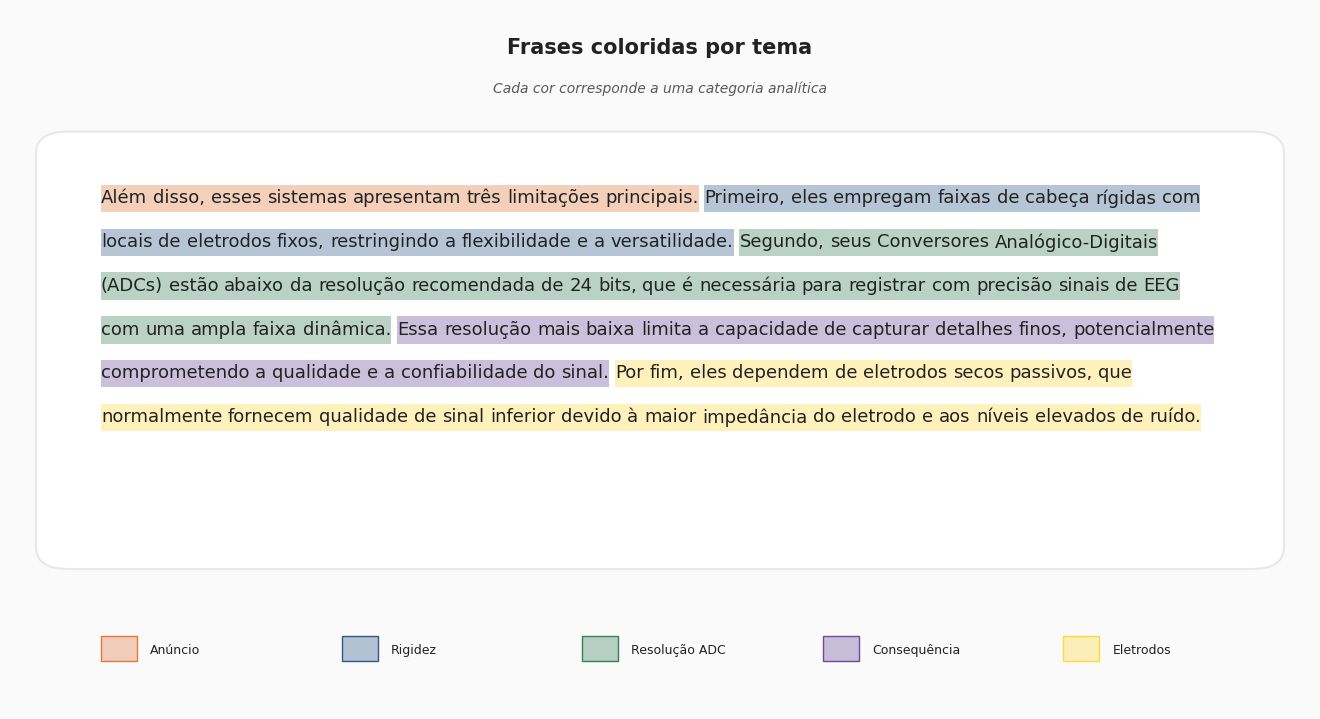

In [5]:
# Frases coloridas

def frases_coloridas():
    trechos = [
        ("Além disso, esses sistemas apresentam três limitações principais. ", CORES["laranja"], "Anúncio"),
        ("Primeiro, eles empregam faixas de cabeça rígidas com locais de eletrodos fixos, restringindo a flexibilidade e a versatilidade. ", CORES["azul"], "Rigidez"),
        ("Segundo, seus Conversores Analógico-Digitais (ADCs) estão abaixo da resolução recomendada de 24 bits, que é necessária para registrar com precisão sinais de EEG com uma ampla faixa dinâmica. ", CORES["verde"], "Resolução ADC"),
        ("Essa resolução mais baixa limita a capacidade de capturar detalhes finos, potencialmente comprometendo a qualidade e a confiabilidade do sinal. ", CORES["roxo"], "Consequência"),
        ("Por fim, eles dependem de eletrodos secos passivos, que normalmente fornecem qualidade de sinal inferior devido à maior impedância do eletrodo e aos níveis elevados de ruído.", "#FFD93D", "Eletrodos"),
    ]

    alpha_fundo = 0.35

    fig, ax = plt.subplots(figsize=(13, 7))
    fig.patch.set_facecolor(CORES["fundo"])
    fig.subplots_adjust(0, 0, 1, 1)
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 8)
    ax.axis("off")

    ax.text(5, 7.5, "Frases coloridas por tema", ha="center", fontsize=15, fontweight="bold", color=CORES["texto"])
    ax.text(5, 7.05, "Cada cor corresponde a uma categoria analítica", ha="center", fontsize=10, color=CORES["cinza"], style="italic")

    box = FancyBboxPatch((0.4, 1.8), 9.2, 4.6, boxstyle="round,pad=0.2,rounding_size=0.25", facecolor="white", edgecolor=CORES["cinza_claro"], linewidth=1.5)
    ax.add_patch(box)

    fontsize = 13
    estilo = dict(fontsize=fontsize, fontweight="medium", family="sans-serif")

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    inv = ax.transData.inverted()

    def medir(s):
        t = ax.text(0, 0, s, **estilo)
        bb = t.get_window_extent(renderer)
        t.remove()
        p0 = inv.transform((0, 0))
        p1 = inv.transform((bb.width, bb.height))
        return p1[0] - p0[0], p1[1] - p0[1]

    largura = lambda s: medir(s)[0]
    largura_espaco = largura("a a") - largura("aa")
    altura_texto = medir("Ágjpq")[1]

    x_ini, x_max = 0.7, 9.3
    altura_linha = 0.5
    pad_v = 0.04
    x, y = x_ini, 5.95

    itens = []
    for idx, (texto, cor, _) in enumerate(trechos):
        for palavra in texto.split():
            w = largura(palavra)
            if x + w > x_max and x > x_ini:
                x = x_ini
                y -= altura_linha
            itens.append(dict(palavra=palavra, x=x, y=y, w=w, cor=cor, seg=idx))
            x += w + largura_espaco

    for i, it in enumerate(itens):
        w_fundo = it["w"]
        if i + 1 < len(itens):
            prox = itens[i + 1]
            if prox["y"] == it["y"] and prox["seg"] == it["seg"]:
                w_fundo += largura_espaco

        ax.add_patch(Rectangle((it["x"], it["y"] - altura_texto - pad_v), w_fundo, altura_texto + 2 * pad_v, facecolor=to_rgba(it["cor"], alpha_fundo), edgecolor="none", zorder=2))
        ax.text(it["x"], it["y"], it["palavra"], ha="left", va="top", color=CORES["texto"], zorder=3, **estilo)

    # Legenda de cores
    legendas = [(t[2], t[1]) for t in trechos]
    x_leg = 0.7
    for i, (nome, cor) in enumerate(legendas):
        ax.add_patch(Rectangle((x_leg + i*1.85, 0.55), 0.28, 0.28, facecolor=to_rgba(cor, alpha_fundo), edgecolor=cor, linewidth=1))
        ax.text(x_leg + i*1.85 + 0.38, 0.68, nome, ha="left", va="center", fontsize=9, color=CORES["texto"])
    plt.savefig("figs/topico_07_05_01.png", dpi=300, bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.show()

frases_coloridas()

# Destaque de trecho

Também podemos destacar um trecho específico do texto, podendo ser a ideia central dele ou apenas um trecho que queremos dar mais atenção.

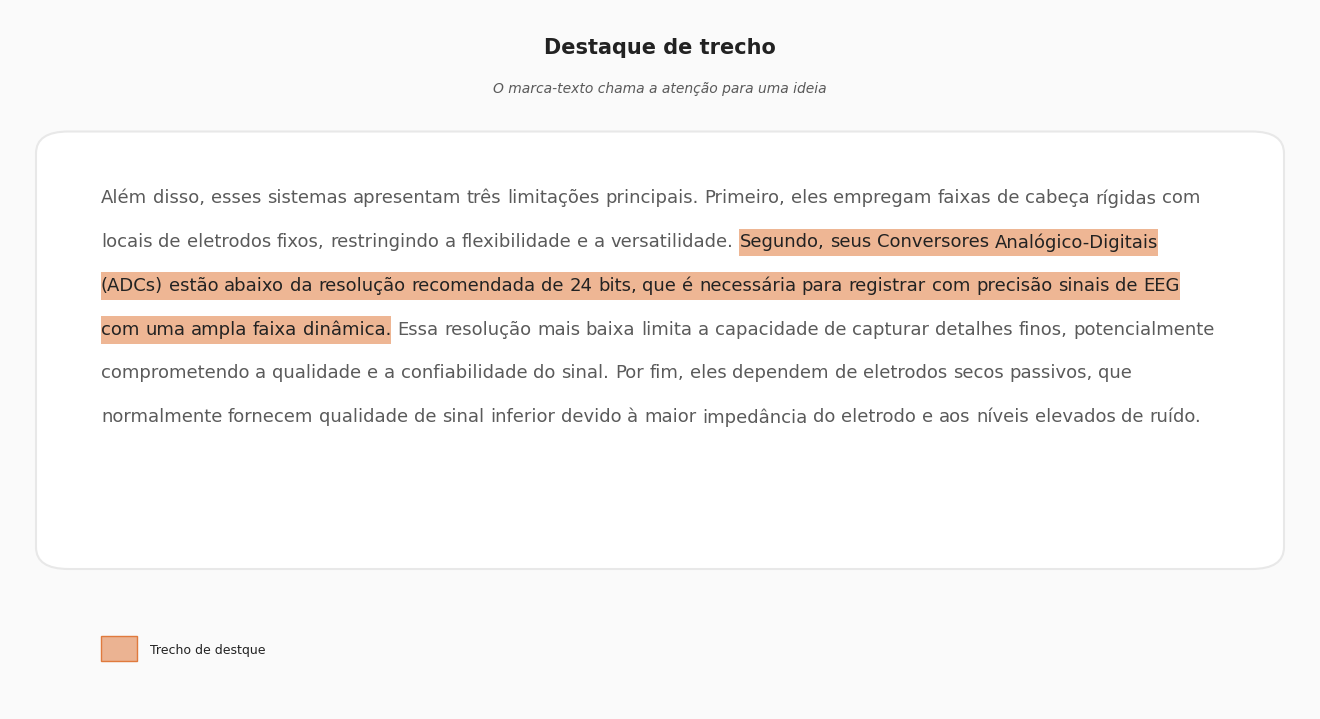

In [6]:
def frases_coloridas():
    trechos = [
        "Além disso, esses sistemas apresentam três limitações principais. ",
        "Primeiro, eles empregam faixas de cabeça rígidas com locais de eletrodos fixos, restringindo a flexibilidade e a versatilidade. ",
        "Segundo, seus Conversores Analógico-Digitais (ADCs) estão abaixo da resolução recomendada de 24 bits, que é necessária para registrar com precisão sinais de EEG com uma ampla faixa dinâmica. ",
        "Essa resolução mais baixa limita a capacidade de capturar detalhes finos, potencialmente comprometendo a qualidade e a confiabilidade do sinal. ",
        "Por fim, eles dependem de eletrodos secos passivos, que normalmente fornecem qualidade de sinal inferior devido à maior impedância do eletrodo e aos níveis elevados de ruído.",
    ]

    idx_destaque = 2
    cor_destaque = CORES["laranja"]
    alpha_fundo = 0.55
    cor_texto_normal = CORES["cinza"]
    cor_texto_destaque = CORES["texto"]

    fig, ax = plt.subplots(figsize=(13, 7))
    fig.patch.set_facecolor(CORES["fundo"])
    fig.subplots_adjust(0, 0, 1, 1)
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 8)
    ax.axis("off")

    ax.text(5, 7.5, "Destaque de trecho", ha="center", fontsize=15, fontweight="bold", color=CORES["texto"])
    ax.text(5, 7.05, "O marca-texto chama a atenção para uma ideia", ha="center", fontsize=10, color=CORES["cinza"], style="italic")

    box = FancyBboxPatch((0.4, 1.8), 9.2, 4.6, boxstyle="round,pad=0.2,rounding_size=0.25", facecolor="white", edgecolor=CORES["cinza_claro"], linewidth=1.5)
    ax.add_patch(box)

    fontsize = 13
    estilo = dict(fontsize=fontsize, fontweight="medium", family="sans-serif")

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    inv = ax.transData.inverted()

    def medir(s):
        t = ax.text(0, 0, s, **estilo)
        bb = t.get_window_extent(renderer)
        t.remove()
        p0 = inv.transform((0, 0))
        p1 = inv.transform((bb.width, bb.height))
        return p1[0] - p0[0], p1[1] - p0[1]

    largura = lambda s: medir(s)[0]
    largura_espaco = largura("a a") - largura("aa")
    altura_texto = medir("Ágjpq")[1]

    x_ini, x_max = 0.7, 9.3
    altura_linha = 0.5
    pad_v = 0.04
    x, y = x_ini, 5.95

    itens = []
    for idx, texto in enumerate(trechos):
        for palavra in texto.split():
            w = largura(palavra)
            if x + w > x_max and x > x_ini:
                x = x_ini
                y -= altura_linha
            itens.append(dict(palavra=palavra, x=x, y=y, w=w, seg=idx))
            x += w + largura_espaco

    for i, it in enumerate(itens):
        destacado = it["seg"] == idx_destaque

        if destacado:
            w_fundo = it["w"]
            if i + 1 < len(itens):
                prox = itens[i + 1]
                if prox["y"] == it["y"] and prox["seg"] == it["seg"]:
                    w_fundo += largura_espaco

            ax.add_patch(Rectangle((it["x"], it["y"] - altura_texto - pad_v), w_fundo, altura_texto + 2 * pad_v, facecolor=to_rgba(cor_destaque, alpha_fundo), edgecolor="none", zorder=2))

        ax.text(it["x"], it["y"], it["palavra"], ha="left", va="top", color=cor_texto_destaque if destacado else cor_texto_normal, zorder=3, **estilo)

    # Legenda
    ax.add_patch(Rectangle((0.7, 0.55), 0.28, 0.28, facecolor=to_rgba(cor_destaque, alpha_fundo), edgecolor=cor_destaque, linewidth=1))
    ax.text(1.08, 0.68, "Trecho de destque", ha="left", va="center", fontsize=9, color=CORES["texto"])

    plt.savefig("figs/topico_07_05_02.png", dpi=300, bbox_inches="tight", facecolor=fig.get_facecolor())
    plt.show()

frases_coloridas()